# 06 - ΔQ(V) and the first baselines

Notebook 05 showed that capacity itself says little about lifetime at cycle 100. The paper's idea is to look at how the **whole discharge curve** changes instead:

ΔQ₁₀₀₋₁₀(V) = Q₁₀₀(V) − Q₁₀(V)

For every voltage on the fixed grid (2.0 to 3.5 V), take the discharge capacity at cycle 100 minus the one at cycle 10. Cells that will die early already show a bigger, more uneven change in this curve, even when their total capacity still looks fine.

The paper's simplest model uses one number per cell, log10(variance of ΔQ), and a straight line to predict log10(cycle life).

Only training cells are used to look at the feature and fit models. The primary test set is used once, for the final numbers. The later batch (secondary test) stays untouched until Stage 3.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.features import delta_q_all, log_var

cells = pd.read_csv("../data/cells_clean.csv").set_index("cell_id")
train = cells[cells["split"] == "train"]
test = cells[cells["split"] == "test_primary"]
print(len(train), "train cells,", len(test), "primary test cells")

41 train cells, 43 primary test cells


## ΔQ curves for all 124 cells

Cycle numbers here are real cycle numbers (the curve for cycle n is stored at position n - 1, see notebook 01). Computing it for every cell now, and saving it, so later notebooks don't need the 8 GB files.

In [2]:
curves, voltage = delta_q_all(set(cells.index), root="../")
curves = curves.loc[cells.index]
print(curves.shape, "| voltage grid", voltage.max(), "to", voltage.min(), "V")
print("missing values:", int(curves.isna().sum().sum()))

curves.columns = [f"v{k}" for k in range(curves.shape[1])]
curves.to_parquet("../data/delta_q_100_10.parquet")
np.save("../data/voltage_grid.npy", voltage)

(124, 1000) | voltage grid 3.5 to 2.0 V
missing values: 0


## What ΔQ looks like (training cells)

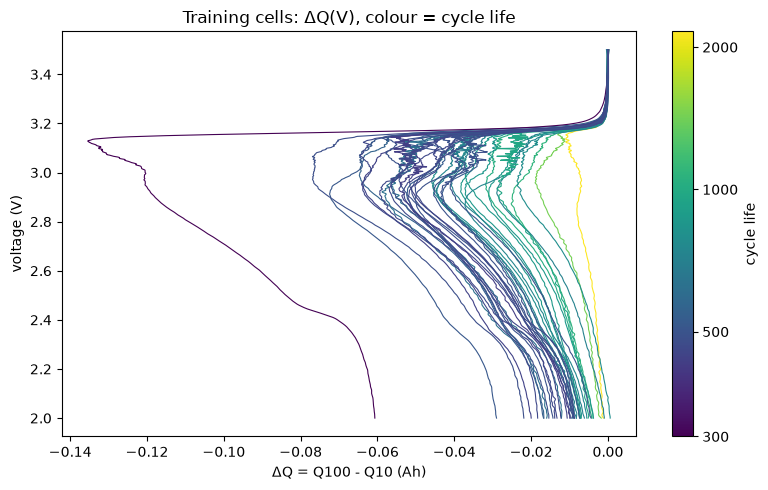

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
cmap = plt.get_cmap("viridis")
norm = plt.Normalize(np.log10(train["cycle_life"]).min(), np.log10(train["cycle_life"]).max())
for cell in train.index:
    ax.plot(curves.loc[cell].values, voltage, color=cmap(norm(np.log10(train.loc[cell, "cycle_life"]))), linewidth=0.8)
ax.set_xlabel("ΔQ = Q100 - Q10 (Ah)")
ax.set_ylabel("voltage (V)")
ax.set_title("Training cells: ΔQ(V), colour = cycle life")
cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax)
ticks = [300, 500, 1000, 2000]
cbar.set_ticks(np.log10(ticks))
cbar.set_ticklabels(ticks)
cbar.set_label("cycle life")
plt.tight_layout()
plt.savefig("../reports/figures/delta_q_train.png", dpi=120)
plt.show()

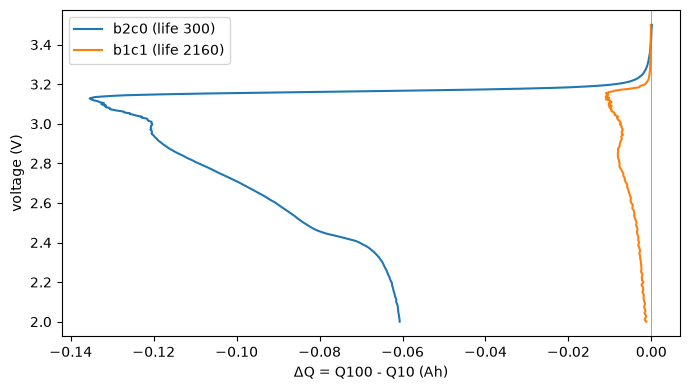

b2c0: min ΔQ -135.4 mAh, variance 1.80e-03
b1c1: min ΔQ -11.0 mAh, variance 9.68e-06


In [4]:
short = train["cycle_life"].idxmin()
long = train["cycle_life"].idxmax()
fig, ax = plt.subplots(figsize=(7, 4))
for cell in [short, long]:
    ax.plot(curves.loc[cell].values, voltage, label=f"{cell} (life {train.loc[cell, 'cycle_life']:.0f})")
ax.axvline(0, color="grey", linewidth=0.5)
ax.set_xlabel("ΔQ = Q100 - Q10 (Ah)")
ax.set_ylabel("voltage (V)")
ax.legend()
plt.tight_layout()
plt.show()

for cell in [short, long]:
    print(f"{cell}: min ΔQ {curves.loc[cell].min() * 1000:.1f} mAh, variance {curves.loc[cell].var(ddof=0):.2e}")

## The feature: log10(var(ΔQ))

correlation on training cells: -0.904


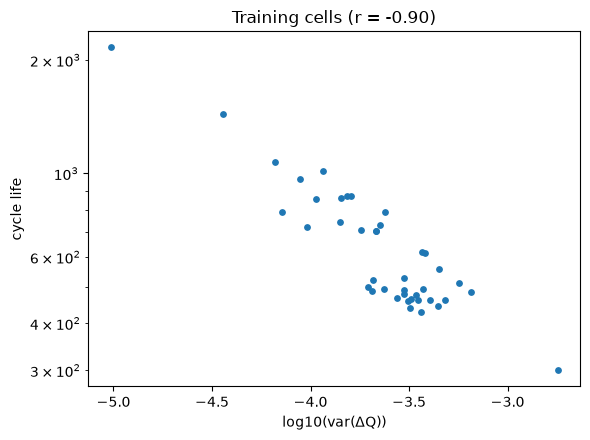

In [5]:
cells["log_var"] = log_var(curves)
cells["log_life"] = np.log10(cells["cycle_life"])
train = cells[cells["split"] == "train"]
test = cells[cells["split"] == "test_primary"]

r = np.corrcoef(train["log_var"], train["log_life"])[0, 1]
print(f"correlation on training cells: {r:.3f}")

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(train["log_var"], train["cycle_life"], s=15)
ax.set_yscale("log")
ax.set_xlabel("log10(var(ΔQ))")
ax.set_ylabel("cycle life")
ax.set_title(f"Training cells (r = {r:.2f})")
plt.tight_layout()
plt.savefig("../reports/figures/log_var_vs_life_train.png", dpi=120)
plt.show()